In [1]:
import os
import copy
import math
import time
import random
import warnings
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter, defaultdict

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader, Subset, ConcatDataset, WeightedRandomSampler
from torchvision import datasets, transforms, models
from torchvision.transforms import InterpolationMode

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

Using device: cuda
GPU Name: Tesla T4


In [2]:
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

EPOCHS_FIRST_TASK = 35
EPOCHS_NEXT_TASKS = 30
BALANCED_FT_EPOCHS = 10

LR_FIRST_TASK = 3e-4
LR_NEXT_TASKS = 1e-4
LR_BALANCED_FT = 7e-5
WEIGHT_DECAY = 1e-4

MEMORY_PER_CLASS = 80
MAX_TASKS = 3
CLASSES_PER_TASK = 3

LABEL_SMOOTHING = 0.03
GRAD_CLIP = 5.0

EXPANSION_OUT_DIM = 512
FREEZE_OLD_BLOCKS = True
FREEZE_BASE_BACKBONE = False

USE_MIXUP = False
USE_CUTMIX = True
CUTMIX_PROB = 0.10
CUTMIX_ALPHA = 0.4

best_macro_f1 = -1.0
best_worst_class_acc = -1.0

print("\nConfiguration Loaded Successfully.")
print(f"IMG_SIZE               : {IMG_SIZE}")
print(f"BATCH_SIZE             : {BATCH_SIZE}")
print(f"EPOCHS_FIRST_TASK      : {EPOCHS_FIRST_TASK}")
print(f"EPOCHS_NEXT_TASKS      : {EPOCHS_NEXT_TASKS}")
print(f"BALANCED_FT_EPOCHS     : {BALANCED_FT_EPOCHS}")
print(f"MEMORY_PER_CLASS       : {MEMORY_PER_CLASS}")
print(f"EXPANSION_OUT_DIM      : {EXPANSION_OUT_DIM}")
print(f"USE_CUTMIX             : {USE_CUTMIX}")
print(f"CUTMIX_PROB            : {CUTMIX_PROB}")


Configuration Loaded Successfully.
IMG_SIZE               : 224
BATCH_SIZE             : 32
EPOCHS_FIRST_TASK      : 35
EPOCHS_NEXT_TASKS      : 30
BALANCED_FT_EPOCHS     : 10
MEMORY_PER_CLASS       : 80
EXPANSION_OUT_DIM      : 512
USE_CUTMIX             : True
CUTMIX_PROB            : 0.1


In [3]:
!pip install -q kaggle

import os

os.environ['KAGGLE_USERNAME'] = "aruna4"
os.environ['KAGGLE_KEY'] = "fabb0946078c052efc978557cfd54477"

!kaggle datasets download -d nodoubttome/skin-cancer9-classesisic
!unzip -q skin-cancer9-classesisic.zip -d skin_cancer_data

base_path = "skin_cancer_data/Skin cancer ISIC The International Skin Imaging Collaboration"

train_path = os.path.join(base_path, "Train")
test_path  = os.path.join(base_path, "Test")

Dataset URL: https://www.kaggle.com/datasets/nodoubttome/skin-cancer9-classesisic
License(s): other
100% 786M/786M [00:09<00:00, 87.7MB/s]



In [4]:
import os

def count_images_in_dataset(path):
    class_counts = {}

    for class_name in os.listdir(path):
        class_path = os.path.join(path, class_name)

        if os.path.isdir(class_path):
            num_images = len([
                f for f in os.listdir(class_path)
                if f.lower().endswith(('.png', '.jpg', '.jpeg'))
            ])
            class_counts[class_name] = num_images

    return class_counts


# Count train and test separately
train_counts = count_images_in_dataset(train_path)
test_counts = count_images_in_dataset(test_path)

print("Train Class Counts:")
for k, v in train_counts.items():
    print(f"{k}: {v}")

print("\nTest Class Counts:")
for k, v in test_counts.items():
    print(f"{k}: {v}")


# Combine train + test
total_per_class = {}
for cls in train_counts:
    total_per_class[cls] = train_counts.get(cls, 0) + test_counts.get(cls, 0)

print("\nTotal Images Per Class (Train + Test):")
for k, v in total_per_class.items():
    print(f"{k}: {v}")


# Total images overall
total_images = sum(total_per_class.values())

print(f"\nTotal Number of Images: {total_images}")

Train Class Counts:
vascular lesion: 139
dermatofibroma: 95
seborrheic keratosis: 77
actinic keratosis: 114
nevus: 357
basal cell carcinoma: 376
pigmented benign keratosis: 462
squamous cell carcinoma: 181
melanoma: 438

Test Class Counts:
vascular lesion: 3
dermatofibroma: 16
seborrheic keratosis: 3
actinic keratosis: 16
nevus: 16
basal cell carcinoma: 16
pigmented benign keratosis: 16
squamous cell carcinoma: 16
melanoma: 16

Total Images Per Class (Train + Test):
vascular lesion: 142
dermatofibroma: 111
seborrheic keratosis: 80
actinic keratosis: 130
nevus: 373
basal cell carcinoma: 392
pigmented benign keratosis: 478
squamous cell carcinoma: 197
melanoma: 454

Total Number of Images: 2357


In [5]:
# BLOCK 2: TRANSFORMS + DATASET LOADING + CLASS INFO

train_transform = transforms.Compose([
    transforms.Resize((256, 256), interpolation=InterpolationMode.BILINEAR),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.88, 1.0), ratio=(0.95, 1.05)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(degrees=12),
    transforms.ColorJitter(brightness=0.08, contrast=0.08, saturation=0.05, hue=0.01),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

full_train_dataset = datasets.ImageFolder(root=train_path, transform=train_transform)
full_test_dataset  = datasets.ImageFolder(root=test_path,  transform=test_transform)

num_total_classes = len(full_train_dataset.classes)
class_names = full_train_dataset.classes
class_to_idx = full_train_dataset.class_to_idx
idx_to_class = {v: k for k, v in class_to_idx.items()}

print("Total Classes:", num_total_classes)
print("\nClass Names:")
print(class_names)

print("\nClass to Index Mapping:")
for k, v in class_to_idx.items():
    print(f"{k} -> {v}")

def get_class_counts(dataset):
    counts = Counter()
    for _, label in dataset.samples:
        counts[label] += 1
    return counts

train_counts_idx = get_class_counts(full_train_dataset)
test_counts_idx = get_class_counts(full_test_dataset)

print("\nTrain Class Counts:")
for idx in range(num_total_classes):
    print(f"{idx_to_class[idx]}: {train_counts_idx[idx]}")

print("\nTest Class Counts:")
for idx in range(num_total_classes):
    print(f"{idx_to_class[idx]}: {test_counts_idx[idx]}")

print("\nTotal Images Per Class (Train + Test):")
for idx in range(num_total_classes):
    total_count = train_counts_idx[idx] + test_counts_idx[idx]
    print(f"{idx_to_class[idx]}: {total_count}")

print("\nTotal Number of Images:", len(full_train_dataset) + len(full_test_dataset))

Total Classes: 9

Class Names:
['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma', 'melanoma', 'nevus', 'pigmented benign keratosis', 'seborrheic keratosis', 'squamous cell carcinoma', 'vascular lesion']

Class to Index Mapping:
actinic keratosis -> 0
basal cell carcinoma -> 1
dermatofibroma -> 2
melanoma -> 3
nevus -> 4
pigmented benign keratosis -> 5
seborrheic keratosis -> 6
squamous cell carcinoma -> 7
vascular lesion -> 8

Train Class Counts:
actinic keratosis: 114
basal cell carcinoma: 376
dermatofibroma: 95
melanoma: 438
nevus: 357
pigmented benign keratosis: 462
seborrheic keratosis: 77
squamous cell carcinoma: 181
vascular lesion: 139

Test Class Counts:
actinic keratosis: 16
basal cell carcinoma: 16
dermatofibroma: 16
melanoma: 16
nevus: 16
pigmented benign keratosis: 16
seborrheic keratosis: 3
squamous cell carcinoma: 16
vascular lesion: 3

Total Images Per Class (Train + Test):
actinic keratosis: 130
basal cell carcinoma: 392
dermatofibroma: 111
melanoma: 454
ne

In [6]:
# BLOCK 3: TASK SPLITS + SUBSET HELPERS + DATALOADERS

task_splits_names = [
    ["actinic keratosis", "basal cell carcinoma", "dermatofibroma"],
    ["melanoma", "nevus", "pigmented benign keratosis"],
    ["seborrheic keratosis", "squamous cell carcinoma", "vascular lesion"]
]

task_splits = []
for task in task_splits_names:
    task_splits.append([class_to_idx[name] for name in task])

print("Task Splits (Index Form):")
for i, task in enumerate(task_splits, 1):
    print(f"Task {i}: {task} -> {[idx_to_class[x] for x in task]}")

def get_subset_by_classes(dataset, class_indices):
    selected_indices = [i for i, (_, label) in enumerate(dataset.samples) if label in class_indices]
    return Subset(dataset, selected_indices)

def get_labels_from_subset(subset):
    labels = []
    base_dataset = subset.dataset
    for i in subset.indices:
        _, label = base_dataset.samples[i]
        labels.append(label)
    return labels

def create_weighted_sampler(subset, seen_classes=None):
    labels = get_labels_from_subset(subset)
    count_dict = Counter(labels)

    sample_weights = []
    for lbl in labels:
        sample_weights.append(1.0 / (count_dict[lbl] + 1e-8))

    sample_weights = torch.DoubleTensor(sample_weights)
    sampler = WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(sample_weights),
        replacement=True
    )
    return sampler, count_dict

def build_loader(subset, train=True, batch_size=BATCH_SIZE):
    if train:
        sampler, count_dict = create_weighted_sampler(subset)
        loader = DataLoader(
            subset,
            batch_size=batch_size,
            sampler=sampler,
            num_workers=NUM_WORKERS,
            pin_memory=True,
            drop_last=False
        )
        return loader, count_dict
    else:
        loader = DataLoader(
            subset,
            batch_size=batch_size,
            shuffle=False,
            num_workers=NUM_WORKERS,
            pin_memory=True,
            drop_last=False
        )
        return loader, None

task_train_subsets = []
task_test_subsets = []

for task_id, class_ids in enumerate(task_splits):
    tr_subset = get_subset_by_classes(full_train_dataset, class_ids)
    te_subset = get_subset_by_classes(full_test_dataset, class_ids)
    task_train_subsets.append(tr_subset)
    task_test_subsets.append(te_subset)

print("\nTask-wise Dataset Sizes:")
for t in range(len(task_splits)):
    print(f"Task {t+1} Train Size: {len(task_train_subsets[t])}")
    print(f"Task {t+1} Test Size : {len(task_test_subsets[t])}")
    print(f"Task {t+1} Classes   : {[idx_to_class[c] for c in task_splits[t]]}")
    print("-" * 40)

Task Splits (Index Form):
Task 1: [0, 1, 2] -> ['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma']
Task 2: [3, 4, 5] -> ['melanoma', 'nevus', 'pigmented benign keratosis']
Task 3: [6, 7, 8] -> ['seborrheic keratosis', 'squamous cell carcinoma', 'vascular lesion']

Task-wise Dataset Sizes:
Task 1 Train Size: 585
Task 1 Test Size : 48
Task 1 Classes   : ['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma']
----------------------------------------
Task 2 Train Size: 1257
Task 2 Test Size : 48
Task 2 Classes   : ['melanoma', 'nevus', 'pigmented benign keratosis']
----------------------------------------
Task 3 Train Size: 397
Task 3 Test Size : 22
Task 3 Classes   : ['seborrheic keratosis', 'squamous cell carcinoma', 'vascular lesion']
----------------------------------------


In [7]:
# BLOCK 4: CLASS WEIGHTS + CUTMIX + CIL METRIC HELPERS

def compute_class_weights_from_subset(subset, seen_classes):
    labels = get_labels_from_subset(subset)
    counts = Counter(labels)

    weights = []
    for c in seen_classes:
        weights.append(1.0 / (counts.get(c, 1) + 1e-8))

    weights = np.array(weights, dtype=np.float32)
    weights = weights / weights.sum() * len(weights)
    return torch.tensor(weights, dtype=torch.float32, device=device)

def rand_bbox(size, lam):
    W = size[2]
    H = size[3]
    cut_rat = np.sqrt(1.0 - lam)
    cut_w = int(W * cut_rat)
    cut_h = int(H * cut_rat)

    cx = np.random.randint(W)
    cy = np.random.randint(H)

    x1 = np.clip(cx - cut_w // 2, 0, W)
    y1 = np.clip(cy - cut_h // 2, 0, H)
    x2 = np.clip(cx + cut_w // 2, 0, W)
    y2 = np.clip(cy + cut_h // 2, 0, H)

    return x1, y1, x2, y2

def apply_cutmix(images, labels, alpha=1.0):
    lam = np.random.beta(alpha, alpha)
    rand_index = torch.randperm(images.size(0)).to(images.device)

    target_a = labels
    target_b = labels[rand_index]

    x1, y1, x2, y2 = rand_bbox(images.size(), lam)
    images[:, :, y1:y2, x1:x2] = images[rand_index, :, y1:y2, x1:x2]

    lam = 1 - ((x2 - x1) * (y2 - y1) / (images.size(-1) * images.size(-2)))
    return images, target_a, target_b, lam


acc_matrix = np.zeros((MAX_TASKS, MAX_TASKS), dtype=np.float32)
task_average_accuracies = []

def compute_cil_metrics(acc_matrix, current_task_id):
    # Average Accuracy after current task
    aa = np.mean(acc_matrix[current_task_id, :current_task_id+1])

    # Average Incremental Accuracy
    aia = np.mean([
        np.mean(acc_matrix[i, :i+1]) for i in range(current_task_id + 1)
    ])

    # Forgetting
    if current_task_id == 0:
        forgetting = 0.0
        bwt = 0.0
    else:
        forgetting_values = []
        bwt_values = []

        for old_task in range(current_task_id):
            best_past = np.max(acc_matrix[:current_task_id, old_task])
            current_acc = acc_matrix[current_task_id, old_task]
            forgetting_values.append(best_past - current_acc)
            bwt_values.append(current_acc - acc_matrix[old_task, old_task])

        forgetting = np.mean(forgetting_values) if len(forgetting_values) > 0 else 0.0
        bwt = np.mean(bwt_values) if len(bwt_values) > 0 else 0.0

    return aa, aia, forgetting, bwt

print("Utility functions ready.")
print("acc_matrix shape:", acc_matrix.shape)

Utility functions ready.
acc_matrix shape: (3, 3)


In [8]:
class ClassBalancedFocalLoss(nn.Module):
    def __init__(self, samples_per_class, beta=0.999, gamma=1.5, label_smoothing=0.0):
        super().__init__()
        effective_num = 1.0 - np.power(beta, samples_per_class)
        weights = (1.0 - beta) / (effective_num + 1e-8)
        weights = weights / np.sum(weights) * len(samples_per_class)
        self.weights = torch.tensor(weights, dtype=torch.float32, device=device)
        self.gamma = gamma
        self.label_smoothing = label_smoothing

    def forward(self, logits, targets):
        ce = F.cross_entropy(
            logits,
            targets,
            weight=self.weights,
            reduction='none',
            label_smoothing=self.label_smoothing
        )
        pt = torch.exp(-ce)
        loss = ((1 - pt) ** self.gamma) * ce
        return loss.mean()

In [9]:
def build_logit_adjustment(counts_dict, seen_classes, tau=1.0):
    freqs = np.array([counts_dict.get(c, 1) for c in seen_classes], dtype=np.float32)
    probs = freqs / np.sum(freqs)
    adjust = tau * np.log(probs + 1e-12)
    return torch.tensor(adjust, dtype=torch.float32, device=device)

In [10]:
# BLOCK 5: VIT-BASED DYNAMIC EXPANDABLE REPRESENTATION

class DERViTB16(nn.Module):
    def __init__(self, num_classes=9, expansion_dim=256, freeze_base_backbone=True):
        super().__init__()

        # Base ViT-B/16 backbone
        self.vit = models.vit_b_16(weights=models.ViT_B_16_Weights.IMAGENET1K_V1)
        self.backbone = self.vit.encoder
        self.backbone_out_dim = self.vit.hidden_dim
        self.expansion_dim = expansion_dim
        self.num_classes = num_classes

        # Task-specific expansion blocks
        self.expansion_blocks = nn.ModuleList()

        # Unified classifier over concatenated features
        self.classifier = None
        self.current_total_dim = 0

        # Keep track of task count
        self.num_tasks_added = 0

        if freeze_base_backbone:
            for p in self.vit.parameters():
                p.requires_grad = False

        print("Base ViT-B/16 loaded successfully.")
        print("Backbone output dimension:", self.backbone_out_dim)

    def add_task_block(self):
        block = nn.Sequential(
            nn.Linear(self.backbone_out_dim, 512),
            nn.ReLU(inplace=True),
            nn.LayerNorm(512),
            nn.Dropout(0.20),

            nn.Linear(512, self.expansion_dim),
            nn.ReLU(inplace=True),
            nn.LayerNorm(self.expansion_dim),
            nn.Dropout(0.20)
        )

        self.expansion_blocks.append(block)
        self.num_tasks_added += 1

        # Update classifier
        self.current_total_dim = self.num_tasks_added * self.expansion_dim
        self.classifier = nn.Linear(self.current_total_dim, self.num_classes)

        print(f"Added expansion block for Task {self.num_tasks_added}")
        print(f"Current total representation dimension: {self.current_total_dim}")

    def freeze_old_expansion_blocks(self):
        if len(self.expansion_blocks) <= 1:
            return

        for block in self.expansion_blocks[:-1]:
            for p in block.parameters():
                p.requires_grad = False
            block.eval()

        print("Old expansion blocks frozen and set to eval mode.")

    def unfreeze_latest_block_and_classifier(self):
        for p in self.expansion_blocks[-1].parameters():
            p.requires_grad = True
        for p in self.classifier.parameters():
            p.requires_grad = True

    def forward_backbone(self, x):
        x = self.vit._process_input(x)
        n = x.shape[0]

        cls_token = self.vit.class_token.expand(n, -1, -1)
        x = torch.cat((cls_token, x), dim=1)

        x = x + self.vit.encoder.pos_embedding
        x = self.vit.encoder.dropout(x)
        x = self.vit.encoder.layers(x)
        x = self.vit.encoder.ln(x)

        # CLS token feature
        x = x[:, 0]
        return x

    def forward(self, x):
        base_feat = self.forward_backbone(x)

        expanded_feats = []
        for block in self.expansion_blocks:
            expanded_feats.append(block(base_feat))

        if len(expanded_feats) == 0:
            raise ValueError("No expansion blocks found. Call add_task_block() first.")

        concat_feat = torch.cat(expanded_feats, dim=1)
        logits = self.classifier(concat_feat)

        return logits, concat_feat, base_feat

# Build model
model = DERViTB16(
    num_classes=num_total_classes,
    expansion_dim=EXPANSION_OUT_DIM,
    freeze_base_backbone=FREEZE_BASE_BACKBONE
).to(device)

# Add first task block initially
model.add_task_block()
model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("\nModel Summary:")
print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")
print(f"Number of classes    : {num_total_classes}")

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:03<00:00, 109MB/s] 


Base ViT-B/16 loaded successfully.
Backbone output dimension: 768
Added expansion block for Task 1
Current total representation dimension: 512

Model Summary:
Total parameters     : 87,230,705
Trainable parameters : 87,230,705
Number of classes    : 9


In [11]:
def configure_backbone_trainability(model, current_task_id):
    # Freeze whole ViT first
    for p in model.vit.parameters():
        p.requires_grad = False

    # Unfreeze last 4 transformer encoder layers
    for name, param in model.vit.named_parameters():
        if (
            "encoder.layers.encoder_layer_8" in name or
            "encoder.layers.encoder_layer_9" in name or
            "encoder.layers.encoder_layer_10" in name or
            "encoder.layers.encoder_layer_11" in name
        ):
            param.requires_grad = True

    # For Task 1, allow a bit more adaptation
    if current_task_id == 0:
        for name, param in model.vit.named_parameters():
            if (
                "encoder.layers.encoder_layer_7" in name or
                "encoder.layers.encoder_layer_8" in name or
                "encoder.layers.encoder_layer_9" in name or
                "encoder.layers.encoder_layer_10" in name or
                "encoder.layers.encoder_layer_11" in name
            ):
                param.requires_grad = True

    print("Backbone trainability configured for current task.")

In [12]:
# BLOCK 6: EXEMPLAR MEMORY + HERDING SELECTION

memory_data = []
memory_labels = []

class MemoryDataset(Dataset):
    def __init__(self, memory_data, memory_labels):
        self.memory_data = memory_data
        self.memory_labels = memory_labels

    def __len__(self):
        return len(self.memory_data)

    def __getitem__(self, idx):
        return self.memory_data[idx], self.memory_labels[idx]

def extract_features_for_subset(model, subset, batch_size=32):
    loader = DataLoader(
        subset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    model.eval()
    all_feats = []
    all_labels = []
    all_imgs = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            _, concat_feat, _ = model(images)
            feats = F.normalize(concat_feat, p=2, dim=1)

            all_feats.append(feats.cpu())
            all_labels.append(labels.cpu())
            all_imgs.append(images.cpu())

    all_feats = torch.cat(all_feats, dim=0)
    all_labels = torch.cat(all_labels, dim=0)
    all_imgs = torch.cat(all_imgs, dim=0)

    return all_feats, all_labels, all_imgs

def build_classwise_subset(full_subset, target_class):
    base_dataset = full_subset.dataset
    selected_indices = []

    for idx in full_subset.indices:
        _, label = base_dataset.samples[idx]
        if label == target_class:
            selected_indices.append(idx)

    return Subset(base_dataset, selected_indices)

def herd_select_exemplars(model, subset, target_class, m):
    cls_subset = build_classwise_subset(subset, target_class)

    if len(cls_subset) == 0:
        return [], []

    feats, labels, imgs = extract_features_for_subset(model, cls_subset, batch_size=BATCH_SIZE)

    feats = F.normalize(feats, p=2, dim=1)
    class_mean = feats.mean(dim=0, keepdim=True)
    class_mean = F.normalize(class_mean, p=2, dim=1)

    distances = torch.norm(feats - class_mean, dim=1)
    sorted_indices = torch.argsort(distances)[:min(m, len(distances))]

    selected_imgs = [imgs[i] for i in sorted_indices]
    selected_labels = [int(labels[i].item()) for i in sorted_indices]

    return selected_imgs, selected_labels

def update_memory(model, seen_classes, train_subsets_seen, memory_per_class=40):
    global memory_data, memory_labels

    new_memory_data = []
    new_memory_labels = []

    merged_indices = []
    base_dataset = train_subsets_seen[0].dataset

    for subset in train_subsets_seen:
        merged_indices.extend(subset.indices)

    merged_subset = Subset(base_dataset, merged_indices)

    for cls in seen_classes:
        selected_imgs, selected_labels = herd_select_exemplars(
            model=model,
            subset=merged_subset,
            target_class=cls,
            m=memory_per_class
        )

        new_memory_data.extend(selected_imgs)
        new_memory_labels.extend(selected_labels)

    memory_data = new_memory_data
    memory_labels = new_memory_labels

In [13]:
def kd_loss_fn(student_logits, teacher_logits, temperature=2.0):
    student_log_probs = F.log_softmax(student_logits / temperature, dim=1)
    teacher_probs = F.softmax(teacher_logits / temperature, dim=1)
    loss = F.kl_div(student_log_probs, teacher_probs, reduction='batchmean')
    loss = loss * (temperature ** 2)
    return loss

In [14]:
# BLOCK 7: EVALUATION FUNCTIONS

def evaluate_seen_classes(model, test_subset, seen_classes):
    loader = DataLoader(
        test_subset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    model.eval()
    correct = 0
    total = 0

    class_correct = defaultdict(int)
    class_total = defaultdict(int)

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits, _, _ = model(images)
            logits_seen = logits[:, seen_classes]

            pred_idx = torch.argmax(logits_seen, dim=1)
            preds = torch.tensor(seen_classes, device=device)[pred_idx]

            correct += (preds == labels).sum().item()
            total += labels.size(0)

            for y_true, y_pred in zip(labels, preds):
                class_total[int(y_true.item())] += 1
                if y_true == y_pred:
                    class_correct[int(y_true.item())] += 1

    task_acc = correct / total if total > 0 else 0.0
    class_acc = {}

    for cls in seen_classes:
        if class_total[cls] > 0:
            class_acc[cls] = class_correct[cls] / class_total[cls]
        else:
            class_acc[cls] = 0.0

    return task_acc, class_acc

def evaluate_task_wise_matrix(model, current_task_id):
    seen_tasks = current_task_id + 1
    seen_classes = []

    for t in range(seen_tasks):
        seen_classes.extend(task_splits[t])

    for eval_task in range(seen_tasks):
        test_subset = task_test_subsets[eval_task]
        task_classes = task_splits[eval_task]

        loader = DataLoader(
            test_subset,
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=NUM_WORKERS,
            pin_memory=True
        )

        model.eval()
        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in loader:
                images = images.to(device)
                labels = labels.to(device)

                logits, _, _ = model(images)

                # CIL-style evaluation among all seen classes
                logits_seen = logits[:, seen_classes]
                pred_idx = torch.argmax(logits_seen, dim=1)
                preds = torch.tensor(seen_classes, device=device)[pred_idx]

                correct += (preds == labels).sum().item()
                total += labels.size(0)

        acc = correct / total if total > 0 else 0.0
        acc_matrix[current_task_id, eval_task] = acc

def print_evaluation_summary(model, current_task_id):
    seen_classes = []
    for t in range(current_task_id + 1):
        seen_classes.extend(task_splits[t])

    current_test_subset = task_test_subsets[current_task_id]

    print(f"\n--- Evaluation After Task {current_task_id + 1} ---\n")

    task_acc, class_acc = evaluate_seen_classes(model, current_test_subset, seen_classes)

    print(f"Task {current_task_id + 1} Accuracy: {task_acc:.4f}")
    print("Class-wise Accuracy:")
    for cls in seen_classes:
        if cls in task_splits[current_task_id]:
            print(f"  {idx_to_class[cls]}: {class_acc.get(cls, 0.0):.4f}")

    if len(class_acc) > 0:
        current_task_class_acc = {cls: class_acc[cls] for cls in task_splits[current_task_id]}
        worst_cls = min(current_task_class_acc, key=current_task_class_acc.get)
        print(f"Worst-class Accuracy: {idx_to_class[worst_cls]} = {current_task_class_acc[worst_cls]:.4f}")

    evaluate_task_wise_matrix(model, current_task_id)
    aa, aia, forgetting, bwt = compute_cil_metrics(acc_matrix, current_task_id)

    print(f"\n===== CIL Metrics After Task {current_task_id + 1} =====")
    print(f"Average Accuracy (AA): {aa:.4f}")
    print(f"Average Incremental Accuracy (AIA): {aia:.4f}")
    print(f"Forgetting (F): {forgetting:.4f}")
    print(f"Backward Transfer (BWT): {bwt:.4f}")

In [15]:
# BLOCK 8: TRAINING + BALANCED FINE-TUNING

def build_combined_train_dataset(current_task_id):
    current_subset = task_train_subsets[current_task_id]

    if len(memory_data) == 0:
        return current_subset

    mem_dataset = MemoryDataset(memory_data, memory_labels)
    combined_dataset = ConcatDataset([current_subset, mem_dataset])
    return combined_dataset

def get_labels_from_concat_dataset(concat_dataset):
    labels = []

    for ds_idx in range(len(concat_dataset.datasets)):
        ds = concat_dataset.datasets[ds_idx]

        if isinstance(ds, Subset):
            base_dataset = ds.dataset
            for idx in ds.indices:
                _, lbl = base_dataset.samples[idx]
                labels.append(lbl)
        else:
            for i in range(len(ds)):
                _, lbl = ds[i]
                labels.append(lbl)

    return labels

def build_weighted_loader_for_combined(dataset, current_task_classes, batch_size=32):
    labels = []
    sources = []

    if isinstance(dataset, ConcatDataset):
        for ds_idx, ds in enumerate(dataset.datasets):
            if isinstance(ds, Subset):
                base_dataset = ds.dataset
                for idx in ds.indices:
                    _, lbl = base_dataset.samples[idx]
                    labels.append(lbl)
                    sources.append(0)
            else:
                for i in range(len(ds)):
                    _, lbl = ds[i]
                    labels.append(lbl)
                    sources.append(1)

    elif isinstance(dataset, Subset):
        labels = get_labels_from_subset(dataset)
        sources = [0] * len(labels)

    else:
        raise ValueError("Unsupported dataset type for weighted loader.")

    counts = Counter(labels)

    # identify weak classes in current task based on raw class counts
    task_class_counts = {cls: counts.get(cls, 0) for cls in current_task_classes}
    sorted_task_classes = sorted(task_class_counts.items(), key=lambda x: x[1])

    weak_classes = set()
    if len(sorted_task_classes) >= 1:
        weak_classes.add(sorted_task_classes[0][0])
    if len(sorted_task_classes) >= 2:
        weak_classes.add(sorted_task_classes[1][0])

    sample_weights = []
    for lbl, src in zip(labels, sources):
        base_w = 1.0 / (counts[lbl] + 1e-8)

        # boost current-task classes
        if lbl in current_task_classes:
            base_w *= 1.8

        # boost weaker classes in current task even more
        if lbl in weak_classes:
            base_w *= 1.5

        # prioritize current task samples over memory samples
        if src == 0:
            base_w *= 1.25
        else:
            base_w *= 0.85

        sample_weights.append(base_w)

    sample_weights = torch.DoubleTensor(sample_weights)

    sampler = WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(sample_weights),
        replacement=True
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        sampler=sampler,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        drop_last=True
    )

    return loader, counts

def train_one_task(model, current_task_id):
    seen_classes = []
    for t in range(current_task_id + 1):
        seen_classes.extend(task_splits[t])

    print("\n==============================")
    print(f"        TASK {current_task_id + 1}")
    print("==============================")
    print("Seen classes inside train:", seen_classes)

    # Add new expansion block for tasks > 1
    if current_task_id > 0:
        model.add_task_block()

        if FREEZE_OLD_BLOCKS:
            model.freeze_old_expansion_blocks()

    model.unfreeze_latest_block_and_classifier()
    model.to(device)

    # Dataset / Loader
    train_dataset = build_combined_train_dataset(current_task_id)
    train_loader, combined_counts = build_weighted_loader_for_combined(train_dataset, batch_size=BATCH_SIZE)

    # Class weights over seen classes
    class_weights = []
    for cls in seen_classes:
        class_weights.append(1.0 / (combined_counts.get(cls, 1) + 1e-8))
    class_weights = np.array(class_weights, dtype=np.float32)
    class_weights = class_weights / class_weights.sum() * len(class_weights)
    class_weights = torch.tensor(class_weights, dtype=torch.float32, device=device)

    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=LABEL_SMOOTHING)

    lr = LR_FIRST_TASK if current_task_id == 0 else LR_NEXT_TASKS

    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.AdamW(trainable_params, lr=lr, weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=(EPOCHS_FIRST_TASK if current_task_id == 0 else EPOCHS_NEXT_TASKS)
    )

    num_epochs = EPOCHS_FIRST_TASK if current_task_id == 0 else EPOCHS_NEXT_TASKS

    # Training loop
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            # map labels to seen-class local index
            label_map = {c: i for i, c in enumerate(seen_classes)}
            local_labels = torch.tensor([label_map[int(y.item())] for y in labels], device=device)

            if USE_CUTMIX and np.random.rand() < CUTMIX_PROB and images.size(0) > 1:
                images, y_a, y_b, lam = apply_cutmix(images, labels, alpha=CUTMIX_ALPHA)
                local_y_a = torch.tensor([label_map[int(y.item())] for y in y_a], device=device)
                local_y_b = torch.tensor([label_map[int(y.item())] for y in y_b], device=device)

                optimizer.zero_grad()
                logits, _, _ = model(images)
                logits_seen = logits[:, seen_classes]

                loss = (
                    lam * criterion(logits_seen, local_y_a) +
                    (1.0 - lam) * criterion(logits_seen, local_y_b)
                )
            else:
                optimizer.zero_grad()
                logits, _, _ = model(images)
                logits_seen = logits[:, seen_classes]
                loss = criterion(logits_seen, local_labels)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(trainable_params, GRAD_CLIP)
            optimizer.step()

            running_loss += loss.item()

        scheduler.step()
        epoch_loss = running_loss / len(train_loader)
        print(f"Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.4f}")

    return model

def balanced_finetuning(model, current_task_id):
    seen_classes = []
    for t in range(current_task_id + 1):
        seen_classes.extend(task_splits[t])

    if len(memory_data) == 0:
        return model

    print("\nRunning Balanced Fine-Tuning...")

    # Freeze full ViT backbone and old blocks during FT
    for p in model.vit.parameters():
        p.requires_grad = False

    if len(model.expansion_blocks) > 1:
        for block in model.expansion_blocks[:-1]:
            for p in block.parameters():
                p.requires_grad = False
            block.eval()

    for p in model.expansion_blocks[-1].parameters():
        p.requires_grad = True

    for p in model.classifier.parameters():
        p.requires_grad = True

    selected_data = []
    selected_labels = []

    class_to_items = defaultdict(list)

    for img, lbl in zip(memory_data, memory_labels):
        if lbl in seen_classes:
            class_to_items[lbl].append(img)

    current_subset = task_train_subsets[current_task_id]
    temp_loader = DataLoader(
        current_subset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    for images, labels in temp_loader:
        for img, lbl in zip(images, labels):
            class_to_items[int(lbl.item())].append(img.cpu())

    min_count = min(len(class_to_items[c]) for c in seen_classes if len(class_to_items[c]) > 0)
    target_count = min(min_count, 60)

    current_task_classes = task_splits[current_task_id]

    for cls in seen_classes:
        if cls in current_task_classes:
            cls_imgs = class_to_items[cls][:min(target_count + 20, len(class_to_items[cls]))]
        else:
            cls_imgs = class_to_items[cls][:target_count]

        selected_data.extend(cls_imgs)
        selected_labels.extend([cls] * len(cls_imgs))

    ft_dataset = MemoryDataset(selected_data, selected_labels)
    ft_loader = DataLoader(
        ft_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        drop_last=True
    )

    seen_counts = Counter(selected_labels)
    samples_per_class = [seen_counts.get(cls, 1) for cls in seen_classes]

    criterion = ClassBalancedFocalLoss(
        samples_per_class=samples_per_class,
        beta=0.999,
        gamma=0.8,
        label_smoothing=LABEL_SMOOTHING
    )

    optimizer = optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=LR_BALANCED_FT,
        weight_decay=WEIGHT_DECAY
    )

    label_map = {c: i for i, c in enumerate(seen_classes)}

    for epoch in range(BALANCED_FT_EPOCHS):
        model.train()
        if len(model.expansion_blocks) > 1:
            for block in model.expansion_blocks[:-1]:
                block.eval()

        running_loss = 0.0

        for images, labels in ft_loader:
            images = images.to(device)
            labels = labels.to(device)

            local_labels = torch.tensor([label_map[int(y.item())] for y in labels], device=device)

            optimizer.zero_grad()
            logits, _, _ = model(images)
            logits_seen = logits[:, seen_classes]

            loss = criterion(logits_seen, local_labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], GRAD_CLIP)
            optimizer.step()

            running_loss += loss.item()

        ft_loss = running_loss / max(len(ft_loader), 1)
        print(f"Balanced FT Epoch {epoch+1}/{BALANCED_FT_EPOCHS}, Loss: {ft_loss:.4f}")

    return model

In [16]:
def kd_loss_fn(student_logits, teacher_logits, temperature=2.0):
    student_log_probs = F.log_softmax(student_logits / temperature, dim=1)
    teacher_probs = F.softmax(teacher_logits / temperature, dim=1)
    loss = F.kl_div(student_log_probs, teacher_probs, reduction='batchmean')
    loss = loss * (temperature ** 2)
    return loss

In [17]:
def configure_backbone_trainability(model, current_task_id):
    # Freeze whole ViT first
    for p in model.vit.parameters():
        p.requires_grad = False

    # Unfreeze last 4 transformer encoder layers
    for name, param in model.vit.named_parameters():
        if (
            "encoder.layers.encoder_layer_8" in name or
            "encoder.layers.encoder_layer_9" in name or
            "encoder.layers.encoder_layer_10" in name or
            "encoder.layers.encoder_layer_11" in name
        ):
            param.requires_grad = True

    # For Task 1, allow a bit more adaptation
    if current_task_id == 0:
        for name, param in model.vit.named_parameters():
            if (
                "encoder.layers.encoder_layer_7" in name or
                "encoder.layers.encoder_layer_8" in name or
                "encoder.layers.encoder_layer_9" in name or
                "encoder.layers.encoder_layer_10" in name or
                "encoder.layers.encoder_layer_11" in name
            ):
                param.requires_grad = True

    print("Backbone trainability configured for current task.")

In [18]:
# BLOCK 9: FULL INCREMENTAL TRAINING

def add_task_block_preserve_classifier(model):
    old_classifier = copy.deepcopy(model.classifier) if model.classifier is not None else None
    old_num_tasks = model.num_tasks_added
    old_total_dim = model.current_total_dim

    # add new block
    block = nn.Sequential(
        nn.Linear(model.backbone_out_dim, 512),
        nn.ReLU(inplace=True),
        nn.LayerNorm(512),
        nn.Dropout(0.20),

        nn.Linear(512, model.expansion_dim),
        nn.ReLU(inplace=True),
        nn.LayerNorm(model.expansion_dim),
        nn.Dropout(0.20)
    )

    model.expansion_blocks.append(block)
    model.num_tasks_added += 1
    model.current_total_dim = model.num_tasks_added * model.expansion_dim

    new_classifier = nn.Linear(model.current_total_dim, model.num_classes)

    # preserve old classifier weights
    with torch.no_grad():
        if old_classifier is not None:
            new_classifier.weight[:, :old_total_dim] = old_classifier.weight
            new_classifier.bias[:] = old_classifier.bias

            # initialize new part lightly
            nn.init.xavier_uniform_(new_classifier.weight[:, old_total_dim:])
        else:
            nn.init.xavier_uniform_(new_classifier.weight)

    model.classifier = new_classifier.to(device)

    print(f"Added expansion block for Task {model.num_tasks_added}")
    print(f"Current total representation dimension: {model.current_total_dim}")
    if old_classifier is not None:
        print("Old classifier weights preserved successfully.")

def evaluate_current_task_macro_f1(model, current_task_id):
    current_task_classes = task_splits[current_task_id]
    current_test_subset = task_test_subsets[current_task_id]

    loader = DataLoader(
        current_test_subset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    model.eval()
    all_targets = []
    all_preds = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits, _, _ = model(images)
            logits_task = logits[:, current_task_classes]
            pred_idx = torch.argmax(logits_task, dim=1)
            preds = torch.tensor(current_task_classes, device=device)[pred_idx]

            all_targets.extend(labels.cpu().numpy().tolist())
            all_preds.extend(preds.cpu().numpy().tolist())

    _, _, macro_f1, _ = precision_recall_fscore_support(
        all_targets, all_preds, average="macro", zero_division=0
    )

    return macro_f1

def evaluate_current_task_worst_class_acc(model, current_task_id):
    current_task_classes = task_splits[current_task_id]
    current_test_subset = task_test_subsets[current_task_id]

    _, class_acc = evaluate_seen_classes(model, current_test_subset, current_task_classes)

    current_task_class_acc = {cls: class_acc.get(cls, 0.0) for cls in current_task_classes}
    worst_acc = min(current_task_class_acc.values())

    return worst_acc

def train_one_task_der(model, current_task_id, teacher_model=None):
    seen_classes = []
    for t in range(current_task_id + 1):
        seen_classes.extend(task_splits[t])

    print("\n==============================")
    print(f"        TASK {current_task_id + 1}")
    print("==============================")
    print("Seen classes inside train:", seen_classes)

    # For tasks > 1, expand model safely
    if current_task_id > 0:
        add_task_block_preserve_classifier(model)

        if FREEZE_OLD_BLOCKS:
            model.freeze_old_expansion_blocks()

    configure_backbone_trainability(model, current_task_id)
    model.unfreeze_latest_block_and_classifier()
    model.to(device)

    # Build combined train set
    train_dataset = build_combined_train_dataset(current_task_id)
    current_task_classes = task_splits[current_task_id]

    train_loader, combined_counts = build_weighted_loader_for_combined(
        train_dataset,
        current_task_classes=current_task_classes,
        batch_size=BATCH_SIZE
    )

    # Class-weighted CE over seen classes
    samples_per_class = [combined_counts.get(cls, 1) for cls in seen_classes]
    criterion = ClassBalancedFocalLoss(
        samples_per_class=samples_per_class,
        beta=0.999,
        gamma=1.5,
        label_smoothing=LABEL_SMOOTHING
    )

    logit_adjustment = build_logit_adjustment(combined_counts, seen_classes, tau=0.8)

    if current_task_id == 0:
        lr = LR_FIRST_TASK
    elif current_task_id == 1:
        lr = LR_NEXT_TASKS
    else:
        lr = LR_NEXT_TASKS * 0.6

    trainable_params = [p for p in model.parameters() if p.requires_grad]

    optimizer = optim.AdamW(trainable_params, lr=lr, weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=(EPOCHS_FIRST_TASK if current_task_id == 0 else EPOCHS_NEXT_TASKS)
    )

    num_epochs = EPOCHS_FIRST_TASK if current_task_id == 0 else EPOCHS_NEXT_TASKS

    best_task_state = None
    best_task_macro_f1 = -1.0
    best_task_worst_acc = -1.0

    label_map = {c: i for i, c in enumerate(seen_classes)}

    for epoch in range(num_epochs):
        model.train()

        if len(model.expansion_blocks) > 1:
            for block in model.expansion_blocks[:-1]:
                block.eval()

        running_loss = 0.0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            task_cutmix_prob = CUTMIX_PROB if current_task_id < 2 else 0.03

            if USE_CUTMIX and np.random.rand() < task_cutmix_prob and images.size(0) > 1:
                images, y_a, y_b, lam = apply_cutmix(images, labels, alpha=CUTMIX_ALPHA)

                local_y_a = torch.tensor([label_map[int(y.item())] for y in y_a], device=device)
                local_y_b = torch.tensor([label_map[int(y.item())] for y in y_b], device=device)

                logits, concat_feat, _ = model(images)
                logits_seen = logits[:, seen_classes] - logit_adjustment.unsqueeze(0)

                ce_loss = (
                    lam * criterion(logits_seen, local_y_a) +
                    (1.0 - lam) * criterion(logits_seen, local_y_b)
                )
            else:
                local_labels = torch.tensor([label_map[int(y.item())] for y in labels], device=device)

                logits, concat_feat, _ = model(images)
                logits_seen = logits[:, seen_classes] - logit_adjustment.unsqueeze(0)

                ce_loss = criterion(logits_seen, local_labels)

            loss = ce_loss

            if teacher_model is not None:
                with torch.no_grad():
                    teacher_logits, _, _ = teacher_model(images)

                old_classes = []
                for t in range(current_task_id):
                    old_classes.extend(task_splits[t])

                if len(old_classes) > 0:
                    kd = kd_loss_fn(
                        logits[:, old_classes],
                        teacher_logits[:, old_classes],
                        temperature=2.0
                    )
                    loss = ce_loss + 0.5 * kd

            loss = ce_loss

            if teacher_model is not None:
                with torch.no_grad():
                    teacher_logits, teacher_feat, _ = teacher_model(images)

                old_classes = []
                for t in range(current_task_id):
                    old_classes.extend(task_splits[t])

                if len(old_classes) > 0:
                    kd = kd_loss_fn(
                        logits[:, old_classes],
                        teacher_logits[:, old_classes],
                        temperature=2.0
                    )
                    loss = ce_loss + 1.0 * kd

            loss.backward()
            torch.nn.utils.clip_grad_norm_(trainable_params, GRAD_CLIP)
            optimizer.step()

            running_loss += loss.item()

        scheduler.step()
        epoch_loss = running_loss / max(len(train_loader), 1)
        if (epoch + 1) % 5 == 0 or (epoch + 1) == num_epochs:
            temp_worst = evaluate_current_task_worst_class_acc(model, current_task_id)
            temp_macro = evaluate_current_task_macro_f1(model, current_task_id)
            #print(f"   -> Current Task Worst-Class Acc: {temp_worst:.4f} | Macro-F1: {temp_macro:.4f}")

        task_macro_f1 = evaluate_current_task_macro_f1(model, current_task_id)
        task_worst_acc = evaluate_current_task_worst_class_acc(model, current_task_id)

        if (task_worst_acc > best_task_worst_acc) or (
            task_worst_acc == best_task_worst_acc and task_macro_f1 > best_task_macro_f1
        ):
            best_task_worst_acc = task_worst_acc
            best_task_macro_f1 = task_macro_f1
            best_task_state = copy.deepcopy(model.state_dict())

        if best_task_state is not None:
            model.load_state_dict(best_task_state)
            #print(f"Loaded best epoch for Task {current_task_id + 1} " f"(Worst-class Acc = {best_task_worst_acc:.4f}, Macro-F1 = {best_task_macro_f1:.4f})")


    return model

# Full training driver
task_train_acc_history = []
task_class_acc_history = []
cil_metric_history = {
    "AA": [],
    "AIA": [],
    "F": [],
    "BWT": []
}

best_model_state = None
best_avg_acc = -1.0

teacher_model = None

for task_id in range(MAX_TASKS):
    if task_id > 0:
        teacher_model = copy.deepcopy(model)
        teacher_model.eval()
        for p in teacher_model.parameters():
            p.requires_grad = False

    model = train_one_task_der(model, task_id, teacher_model=teacher_model)

    if len(memory_data) > 0:
        model = balanced_finetuning(model, task_id)

    print_evaluation_summary(model, task_id)

    # store task-specific eval for later
    seen_classes = []
    for t in range(task_id + 1):
        seen_classes.extend(task_splits[t])

    task_acc, class_acc = evaluate_seen_classes(model, task_test_subsets[task_id], seen_classes)
    task_train_acc_history.append(task_acc)
    task_class_acc_history.append(class_acc)

    aa, aia, forgetting, bwt = compute_cil_metrics(acc_matrix, task_id)
    cil_metric_history["AA"].append(aa)
    cil_metric_history["AIA"].append(aia)
    cil_metric_history["F"].append(forgetting)
    cil_metric_history["BWT"].append(bwt)

    # update memory after evaluation
    seen_train_subsets = [task_train_subsets[t] for t in range(task_id + 1)]
    update_memory(
        model=model,
        seen_classes=seen_classes,
        train_subsets_seen=seen_train_subsets,
        memory_per_class=MEMORY_PER_CLASS
    )

    # compute macro-F1 on current task-aware evaluation
    current_task_classes = task_splits[task_id]
    task_targets = []
    task_preds = []

    loader_eval = DataLoader(
        task_test_subsets[task_id],
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    model.eval()
    with torch.no_grad():
        for images, labels in loader_eval:
            images = images.to(device)
            labels = labels.to(device)

            logits, _, _ = model(images)
            logits_task = logits[:, current_task_classes]
            pred_idx = torch.argmax(logits_task, dim=1)
            preds = torch.tensor(current_task_classes, device=device)[pred_idx]

            task_targets.extend(labels.cpu().numpy().tolist())
            task_preds.extend(preds.cpu().numpy().tolist())

    _, _, macro_f1, _ = precision_recall_fscore_support(
        task_targets, task_preds, average="macro", zero_division=0
    )

    # compute worst current-task class accuracy
    cm_task = confusion_matrix(task_targets, task_preds, labels=current_task_classes)
    per_class_task_acc = cm_task.diagonal() / np.maximum(cm_task.sum(axis=1), 1)
    worst_task_acc = np.min(per_class_task_acc)

    if (worst_task_acc > best_worst_class_acc) or (
        np.isclose(worst_task_acc, best_worst_class_acc) and macro_f1 > best_macro_f1
    ):
        best_worst_class_acc = worst_task_acc
        best_macro_f1 = macro_f1
        best_model_state = copy.deepcopy(model.state_dict())
        print(
            f"\nBest model updated after Task {task_id+1} "
            f"with Worst-Class Acc = {worst_task_acc:.4f} and Macro-F1 = {macro_f1:.4f}"
        )

print("\n==================================================")
print("FULL DER CLASS-INCREMENTAL TRAINING COMPLETED")
print("==================================================")


        TASK 1
Seen classes inside train: [0, 1, 2]
Backbone trainability configured for current task.

--- Evaluation After Task 1 ---

Task 1 Accuracy: 0.8958
Class-wise Accuracy:
  actinic keratosis: 0.8750
  basal cell carcinoma: 0.8750
  dermatofibroma: 0.9375
Worst-class Accuracy: actinic keratosis = 0.8750

===== CIL Metrics After Task 1 =====
Average Accuracy (AA): 0.8958
Average Incremental Accuracy (AIA): 0.8958
Forgetting (F): 0.0000
Backward Transfer (BWT): 0.0000

Best model updated after Task 1 with Worst-Class Acc = 0.8750 and Macro-F1 = 0.8963

        TASK 2
Seen classes inside train: [0, 1, 2, 3, 4, 5]
Added expansion block for Task 2
Current total representation dimension: 1024
Old classifier weights preserved successfully.
Old expansion blocks frozen and set to eval mode.
Backbone trainability configured for current task.

Running Balanced Fine-Tuning...
Balanced FT Epoch 1/10, Loss: 0.4121
Balanced FT Epoch 2/10, Loss: 0.3630
Balanced FT Epoch 3/10, Loss: 0.3518
B

In [19]:
SAVE_PATH_FINAL = "der_vit_b16_final.pth"
SAVE_PATH_BEST  = "der_vit_b16_best.pth"

torch.save(model.state_dict(), SAVE_PATH_FINAL)
print(f"Final model saved to: {SAVE_PATH_FINAL}")

if best_model_state is not None:
    torch.save(best_model_state, SAVE_PATH_BEST)
    print(f"Best model saved to: {SAVE_PATH_BEST}")

print("\nAccuracy Matrix (rows = after training task i, cols = evaluated task j):")
print(acc_matrix)

print("\nFormatted Accuracy Matrix:")
for i in range(MAX_TASKS):
    row_text = " | ".join([f"{acc_matrix[i, j]:.4f}" for j in range(MAX_TASKS)])
    print(f"After Task {i+1}: {row_text}")

print("\nFinal CIL Metric History:")
for key, values in cil_metric_history.items():
    print(f"{key}: {[round(v, 4) for v in values]}")

Final model saved to: der_vit_b16_final.pth
Best model saved to: der_vit_b16_best.pth

Accuracy Matrix (rows = after training task i, cols = evaluated task j):
[[0.8958333 0.        0.       ]
 [0.5833333 0.6458333 0.       ]
 [0.5416667 0.4375    0.6363636]]

Formatted Accuracy Matrix:
After Task 1: 0.8958 | 0.0000 | 0.0000
After Task 2: 0.5833 | 0.6458 | 0.0000
After Task 3: 0.5417 | 0.4375 | 0.6364

Final CIL Metric History:
AA: [np.float32(0.8958), np.float32(0.6146), np.float32(0.5385)]
AIA: [np.float32(0.8958), np.float32(0.7552), np.float32(0.683)]
F: [0.0, np.float32(0.3125), np.float32(0.2812)]
BWT: [0.0, np.float32(-0.3125), np.float32(-0.2812)]


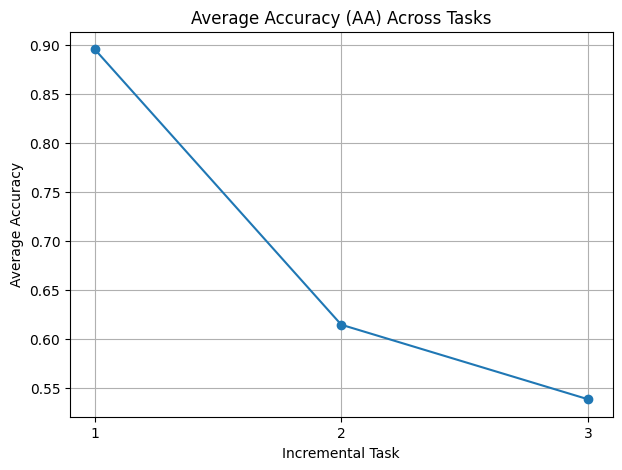

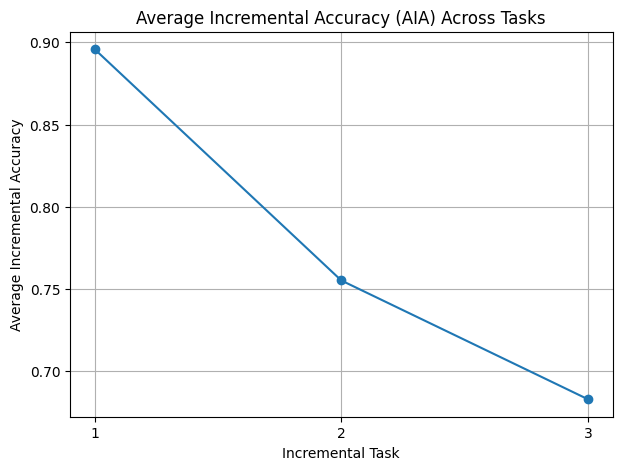

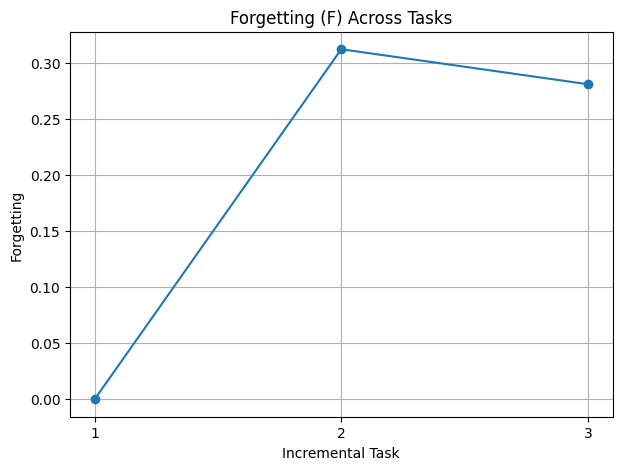

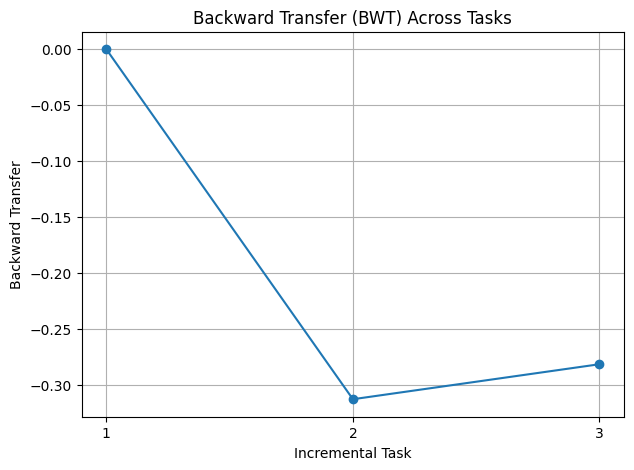

Plots generated successfully.


In [20]:
tasks_axis = np.arange(1, MAX_TASKS + 1)

plt.figure(figsize=(7, 5))
plt.plot(tasks_axis, cil_metric_history["AA"], marker='o')
plt.xticks(tasks_axis)
plt.xlabel("Incremental Task")
plt.ylabel("Average Accuracy")
plt.title("Average Accuracy (AA) Across Tasks")
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(tasks_axis, cil_metric_history["AIA"], marker='o')
plt.xticks(tasks_axis)
plt.xlabel("Incremental Task")
plt.ylabel("Average Incremental Accuracy")
plt.title("Average Incremental Accuracy (AIA) Across Tasks")
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(tasks_axis, cil_metric_history["F"], marker='o')
plt.xticks(tasks_axis)
plt.xlabel("Incremental Task")
plt.ylabel("Forgetting")
plt.title("Forgetting (F) Across Tasks")
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(tasks_axis, cil_metric_history["BWT"], marker='o')
plt.xticks(tasks_axis)
plt.xlabel("Incremental Task")
plt.ylabel("Backward Transfer")
plt.title("Backward Transfer (BWT) Across Tasks")
plt.grid(True)
plt.show()

print("Plots generated successfully.")

In [21]:
from sklearn.metrics import classification_report, accuracy_score, precision_recall_fscore_support

def evaluate_task_aware_overall(model):

    model.eval()

    all_preds = []
    all_targets = []

    with torch.no_grad():

        for task_id, class_indices in enumerate(task_splits):

            test_subset = task_test_subsets[task_id]

            loader = DataLoader(
                test_subset,
                batch_size=BATCH_SIZE,
                shuffle=False,
                num_workers=NUM_WORKERS,
                pin_memory=True
            )

            for images, labels in loader:
                images = images.to(device)
                labels = labels.to(device)

                logits, _, _ = model(images)

                logits_task = logits[:, class_indices]

                pred_idx = torch.argmax(logits_task, dim=1)
                preds = torch.tensor(class_indices, device=device)[pred_idx]

                all_preds.extend(preds.cpu().numpy())
                all_targets.extend(labels.cpu().numpy())

    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)

    accuracy = accuracy_score(all_targets, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_targets, all_preds, average="weighted", zero_division=0
    )

    print("OVERALL PERFORMANCE : ")
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-score : {f1:.4f}")

    print("CLASSIFICATION REPORT : ")
    print(classification_report(
        all_targets,
        all_preds,
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

    return all_targets, all_preds

ta_targets, ta_preds = evaluate_task_aware_overall(model)

OVERALL PERFORMANCE : 
Accuracy : 0.8051
Precision: 0.8264
Recall   : 0.8051
F1-score : 0.7912
CLASSIFICATION REPORT : 
                            precision    recall  f1-score   support

         actinic keratosis     1.0000    0.7500    0.8571        16
      basal cell carcinoma     0.8421    1.0000    0.9143        16
            dermatofibroma     0.8824    0.9375    0.9091        16
                  melanoma     0.6667    0.2500    0.3636        16
                     nevus     0.5556    0.9375    0.6977        16
pigmented benign keratosis     0.8667    0.8125    0.8387        16
      seborrheic keratosis     0.7500    1.0000    0.8571         3
   squamous cell carcinoma     1.0000    0.8750    0.9333        16
           vascular lesion     0.7500    1.0000    0.8571         3

                  accuracy                         0.8051       118
                 macro avg     0.8126    0.8403    0.8031       118
              weighted avg     0.8264    0.8051    0.7912     

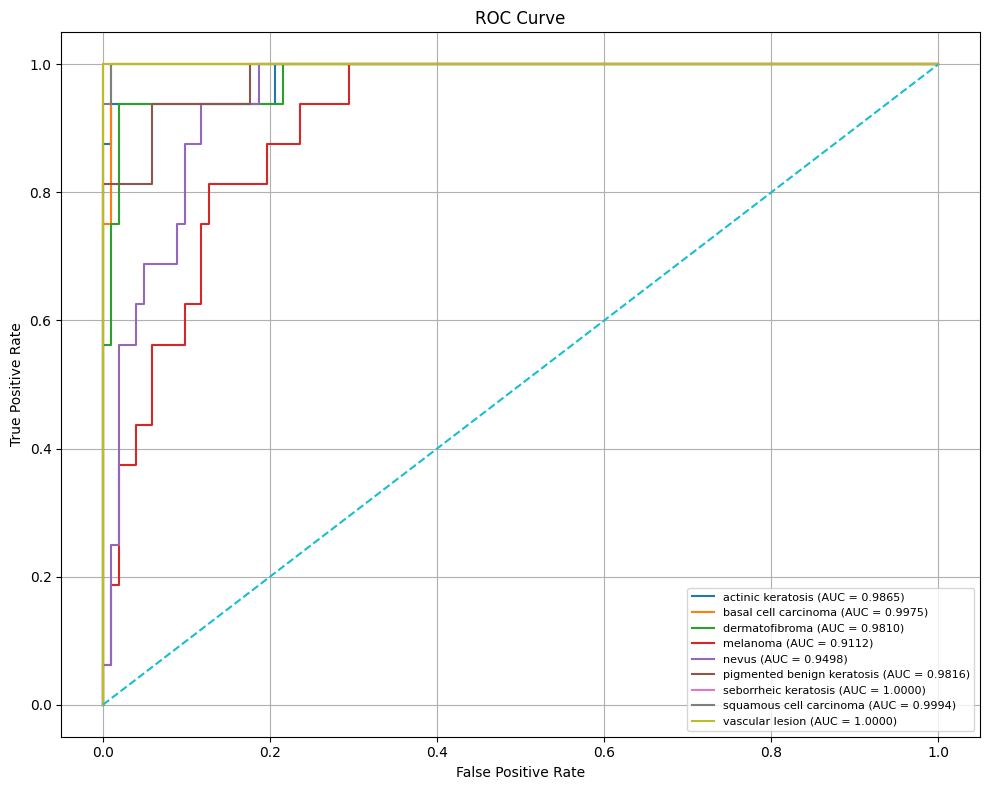

In [22]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

def compute_task_aware_probabilities(model):
    model.eval()

    all_targets = []
    all_probs = []

    with torch.no_grad():
        for task_id, class_indices in enumerate(task_splits):

            test_subset = task_test_subsets[task_id]

            loader = DataLoader(
                test_subset,
                batch_size=BATCH_SIZE,
                shuffle=False,
                num_workers=NUM_WORKERS,
                pin_memory=True
            )

            for images, labels in loader:
                images = images.to(device)
                labels = labels.to(device)

                logits, _, _ = model(images)

                logits_task = logits[:, class_indices]
                probs_task = F.softmax(logits_task, dim=1)

                probs_full = torch.zeros((images.size(0), num_total_classes), device=device)
                probs_full[:, class_indices] = probs_task

                all_probs.append(probs_full.cpu().numpy())
                all_targets.extend(labels.cpu().numpy())

    all_probs = np.concatenate(all_probs, axis=0)
    all_targets = np.array(all_targets)

    return all_targets, all_probs

ta_targets_roc, ta_probs = compute_task_aware_probabilities(model)

y_bin = label_binarize(ta_targets_roc, classes=list(range(num_total_classes)))

fpr = {}
tpr = {}
roc_auc = {}

for i in range(num_total_classes):
    if np.sum(y_bin[:, i]) > 0:
        fpr[i], tpr[i], _ = roc_curve(y_bin[:, i], ta_probs[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(10, 8))
for i in range(num_total_classes):
    if i in roc_auc:
        plt.plot(fpr[i], tpr[i], label=f"{class_names[i]} (AUC = {roc_auc[i]:.4f})")

plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right", fontsize=8)
plt.grid(True)
plt.tight_layout()
plt.show()

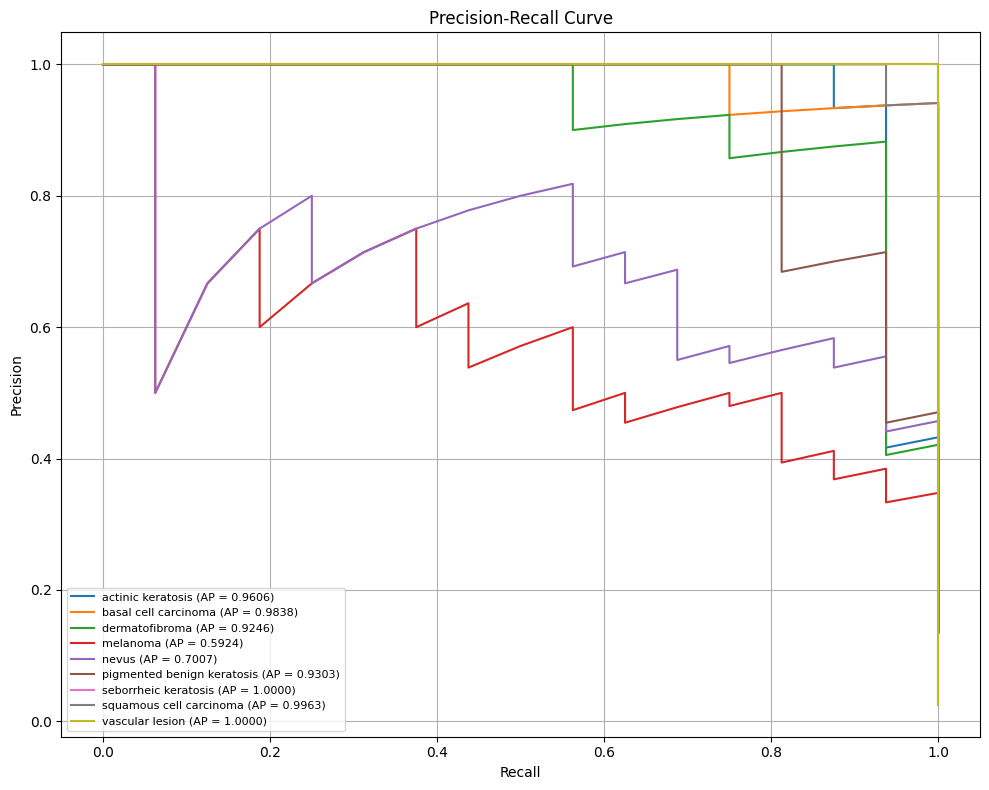

In [23]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision_dict = {}
recall_dict = {}
ap_dict = {}

for i in range(num_total_classes):
    if np.sum(y_bin[:, i]) > 0:
        precision_dict[i], recall_dict[i], _ = precision_recall_curve(y_bin[:, i], ta_probs[:, i])
        ap_dict[i] = average_precision_score(y_bin[:, i], ta_probs[:, i])

plt.figure(figsize=(10, 8))
for i in range(num_total_classes):
    if i in ap_dict:
        plt.plot(recall_dict[i], precision_dict[i], label=f"{class_names[i]} (AP = {ap_dict[i]:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend(loc="lower left", fontsize=8)
plt.grid(True)
plt.tight_layout()
plt.show()

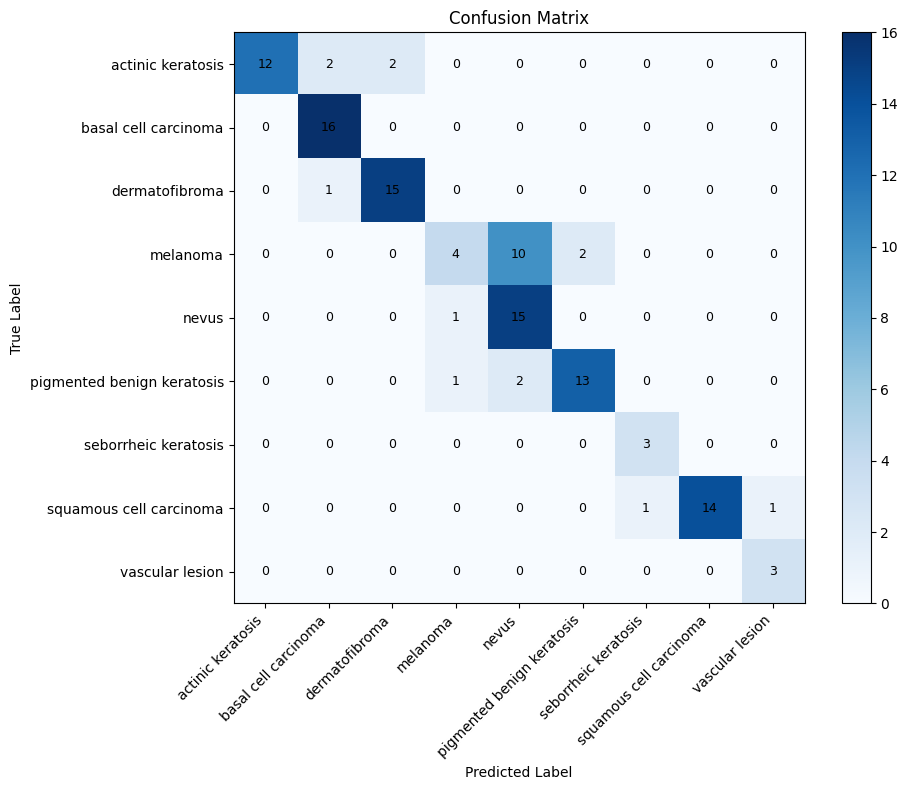

In [24]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

def plot_task_aware_confusion_matrix(model):
    model.eval()

    all_preds = []
    all_targets = []

    with torch.no_grad():
        for task_id, class_indices in enumerate(task_splits):

            test_subset = task_test_subsets[task_id]

            loader = DataLoader(
                test_subset,
                batch_size=BATCH_SIZE,
                shuffle=False,
                num_workers=NUM_WORKERS,
                pin_memory=True
            )

            for images, labels in loader:
                images = images.to(device)
                labels = labels.to(device)

                logits, _, _ = model(images)

                logits_task = logits[:, class_indices]
                pred_idx = torch.argmax(logits_task, dim=1)
                preds = torch.tensor(class_indices, device=device)[pred_idx]

                all_preds.extend(preds.cpu().numpy())
                all_targets.extend(labels.cpu().numpy())

    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)

    cm = confusion_matrix(all_targets, all_preds, labels=list(range(num_total_classes)))

    plt.figure(figsize=(10, 8))
    plt.imshow(cm, interpolation='nearest', cmap='Blues')
    plt.title("Confusion Matrix")
    plt.colorbar()

    tick_marks = np.arange(num_total_classes)
    plt.xticks(tick_marks, class_names, rotation=45, ha='right')
    plt.yticks(tick_marks, class_names)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=9)

    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()
    plt.show()

    return all_targets, all_preds, cm

ta_targets, ta_preds, ta_cm = plot_task_aware_confusion_matrix(model)

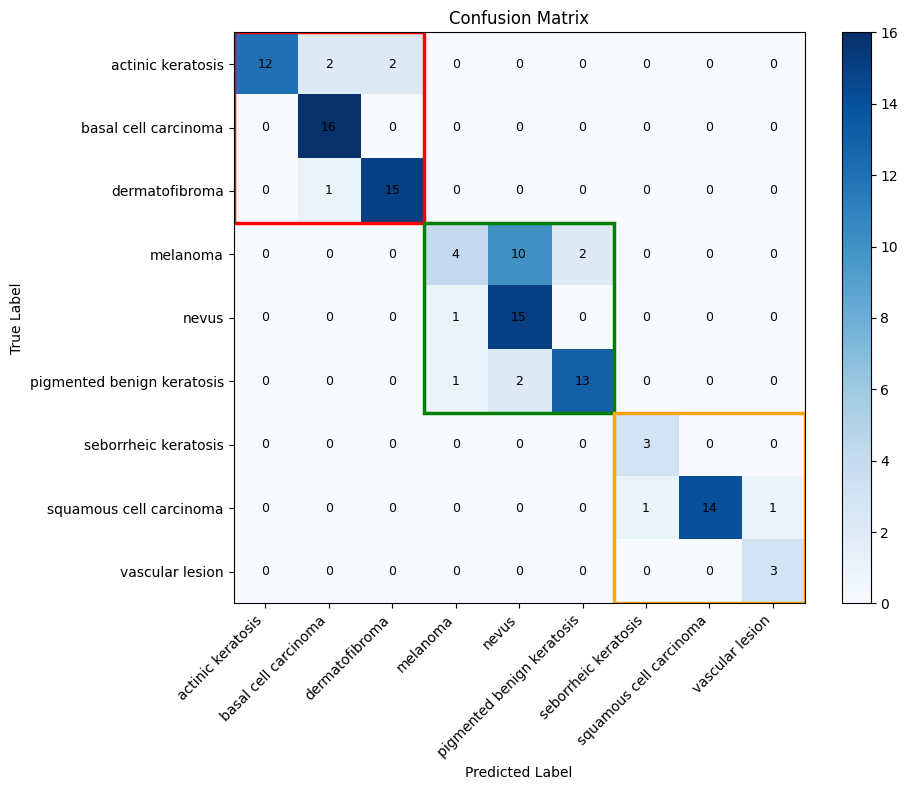

In [25]:
import matplotlib.patches as patches

def plot_highlighted_task_aware_confusion_matrix(cm):
    plt.figure(figsize=(10, 8))
    ax = plt.gca()

    im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
    plt.title("Confusion Matrix")
    plt.colorbar(im)

    tick_marks = np.arange(num_total_classes)
    ax.set_xticks(tick_marks)
    ax.set_yticks(tick_marks)
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.set_yticklabels(class_names)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=9)

    rect1 = patches.Rectangle(
        (-0.5, -0.5), 3, 3,
        linewidth=2.5, edgecolor='red', facecolor='none'
    )
    ax.add_patch(rect1)

    rect2 = patches.Rectangle(
        (2.5, 2.5), 3, 3,
        linewidth=2.5, edgecolor='green', facecolor='none'
    )
    ax.add_patch(rect2)

    rect3 = patches.Rectangle(
        (5.5, 5.5), 3, 3,
        linewidth=2.5, edgecolor='orange', facecolor='none'
    )
    ax.add_patch(rect3)

    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
    plt.tight_layout()
    plt.show()

plot_highlighted_task_aware_confusion_matrix(ta_cm)